# Control: clasificación de audio con red neuronal

**Universitario:** Emily PeÑaranda Anagua


## 1. Librerías


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)


In [2]:
from datasets import load_dataset, Audio

dataset = load_dataset("DBD-research-group/BirdSet", "HSN", trust_remote_code=True)
dataset = dataset.cast_column("audio", Audio(sampling_rate=32_000))

train = dataset["train"]
categorias = train.features["ebird_code"].names

print(dataset)
print("Clases:", len(categorias))
print(categorias)


DatasetDict({
    train: Dataset({
        features: ['audio', 'filepath', 'start_time', 'end_time', 'low_freq', 'high_freq', 'ebird_code', 'ebird_code_multilabel', 'ebird_code_secondary', 'call_type', 'sex', 'lat', 'long', 'length', 'microphone', 'license', 'source', 'local_time', 'detected_events', 'event_cluster', 'peaks', 'quality', 'recordist', 'genus', 'species_group', 'order', 'genus_multilabel', 'species_group_multilabel', 'order_multilabel'],
        num_rows: 5460
    })
    test: Dataset({
        features: ['audio', 'filepath', 'start_time', 'end_time', 'low_freq', 'high_freq', 'ebird_code', 'ebird_code_multilabel', 'ebird_code_secondary', 'call_type', 'sex', 'lat', 'long', 'length', 'microphone', 'license', 'source', 'local_time', 'detected_events', 'event_cluster', 'peaks', 'quality', 'recordist', 'genus', 'species_group', 'order', 'genus_multilabel', 'species_group_multilabel', 'order_multilabel'],
        num_rows: 10296
    })
    test_5s: Dataset({
        features: [

gcrfin 17
whcspa 25
amepip 25
sposan 25
rocwre 25
brebla 25
daejun 25
foxspa 25
clanut 25
moublu 25
casfin 25
mallar3 25
herthr 25
amerob 25
yerwar 25
yelwar 25
dusfly 25
mouchi 25
orcwar 25
warvir 25
norfli 25


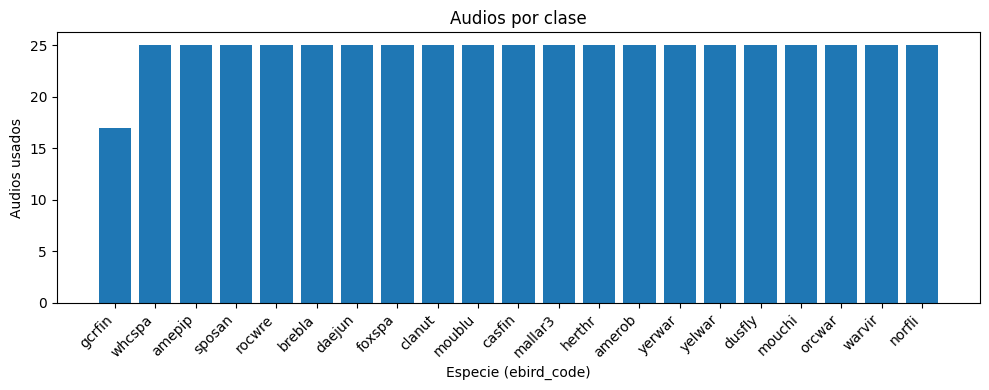

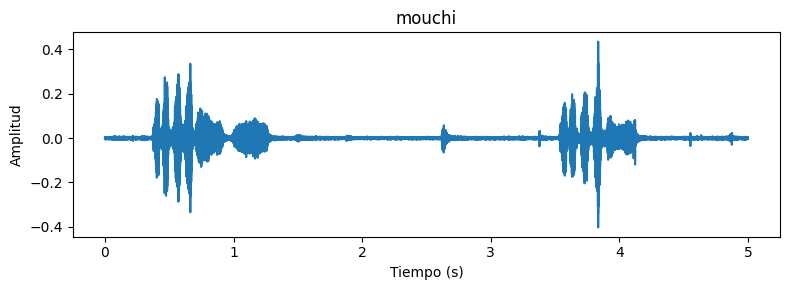

In [3]:
por_clase = 25
max_muestras = 32_000 * 5
codigos = np.array(train["ebird_code"])
rng = np.random.default_rng(42)
elegidos = []

for clase in range(len(categorias)):
    indices = np.where(codigos == clase)[0]
    rng.shuffle(indices)
    elegidos.append(indices[:por_clase])

elegidos = np.concatenate(elegidos)
rng.shuffle(elegidos)

conteo = np.bincount(codigos[elegidos], minlength=len(categorias))
for nombre, cantidad in zip(categorias, conteo):
    print(nombre, int(cantidad))

plt.figure(figsize=(10, 4))
plt.bar(categorias, conteo)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Especie (ebird_code)")
plt.ylabel("Audios usados")
plt.title("Audios por clase")
plt.tight_layout()
plt.show()

muestra_ejemplo = train[int(elegidos[0])]
senal_ejemplo = np.asarray(muestra_ejemplo["audio"]["array"], dtype=np.float32)[:max_muestras]
tiempo = np.arange(len(senal_ejemplo)) / 32_000

plt.figure(figsize=(8, 3))
plt.plot(tiempo, senal_ejemplo)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title(categorias[muestra_ejemplo["ebird_code"]])
plt.tight_layout()
plt.show()


**Balanceo.** Con el tope de 25 audios por especie, ninguna clase aporta más ejemplos que otra. No hace falta copiar ni borrar filas dentro de ese subconjunto.

## 4. Características del audio

La red no recibe la onda cruda. Cada clip se resume en un vector.

Pasos del MFCC:

1. Preénfasis: $y[n] = x[n] - \alpha\, x[n-1]$
2. Ventana de Hamming y transformada de Fourier
3. Frecuencia en escala Mel:

$$
m = 2595 \log_{10}\left(1 + \frac{f}{700}\right)
$$

4. Logaritmo de la energía de cada filtro
5. Transformada del coseno (DCT). Los primeros coeficientes son los MFCC

De cada audio se guardan la media y la desviación de 20 coeficientes. El vector de entrada tiene 40 números.


In [4]:
n_mfcc = 20
n_mels = 26
n_fft = 1024
hop = 512
sr_modelo = 32_000

def vector_mfcc(senal):
    senal = np.asarray(senal, dtype=np.float32)
    if senal.ndim == 2:
        senal = senal.mean(axis=1)
    senal = senal[:max_muestras]
    pico = np.max(np.abs(senal)) if len(senal) else 0.0
    if pico > 0:
        senal = senal / pico
    if len(senal) < 2:
        senal = np.zeros(n_fft, dtype=np.float32)
    senal = np.append(senal[0], senal[1:] - 0.97 * senal[:-1]).astype(np.float32)
    if len(senal) < n_fft:
        senal = np.pad(senal, (0, n_fft - len(senal)))
    n_frames = 1 + (len(senal) - n_fft) // hop
    indices = np.arange(n_fft)[None, :] + hop * np.arange(n_frames)[:, None]
    ventana = np.hamming(n_fft).astype(np.float32)
    marcos = senal[indices] * ventana
    potencia = np.abs(np.fft.rfft(marcos, n=n_fft)) ** 2
    n_freq = potencia.shape[1]
    mel_min = 0.0
    mel_max = 2595 * np.log10(1 + (sr_modelo / 2) / 700)
    puntos_mel = np.linspace(mel_min, mel_max, n_mels + 2)
    puntos_hz = 700 * (10 ** (puntos_mel / 2595) - 1)
    bins = np.floor((n_fft + 1) * puntos_hz / sr_modelo).astype(int)
    bins = np.clip(bins, 0, n_freq - 1)
    filtros = np.zeros((n_mels, n_freq), dtype=np.float32)
    for i in range(n_mels):
        izquierda = bins[i]
        centro = bins[i + 1]
        derecha = bins[i + 2]
        if centro > izquierda:
            filtros[i, izquierda:centro] = (np.arange(izquierda, centro) - izquierda) / (centro - izquierda)
        if derecha > centro:
            filtros[i, centro:derecha] = (derecha - np.arange(centro, derecha)) / (derecha - centro)
    energia = np.maximum(potencia @ filtros.T, 1e-10)
    log_energia = np.log(energia)
    n = np.arange(n_mels)
    k = np.arange(n_mfcc)[:, None]
    dct = np.cos(np.pi * (n + 0.5) * k / n_mels)
    mfcc = log_energia @ dct.T
    return np.concatenate([mfcc.mean(axis=0), mfcc.std(axis=0)]).astype(np.float32)

vectores = []
y = []
for indice in elegidos:
    muestra = train[int(indice)]
    senal = np.asarray(muestra["audio"]["array"], dtype=np.float32)
    vectores.append(vector_mfcc(senal))
    y.append(muestra["ebird_code"])

X = np.vstack(vectores).astype(np.float32)
y = np.array(y, dtype=np.int64)

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)


Forma de X: (517, 40)
Forma de y: (517,)


In [5]:
rng = np.random.default_rng(42)
idx_train = []
idx_test = []

for clase in range(len(categorias)):
    indices = np.where(y == clase)[0]
    rng.shuffle(indices)
    corte = int(len(indices) * 0.8)
    idx_train.append(indices[:corte])
    idx_test.append(indices[corte:])

idx_train = np.concatenate(idx_train)
idx_test = np.concatenate(idx_test)
rng.shuffle(idx_train)
rng.shuffle(idx_test)

X_train = X[idx_train]
X_test = X[idx_test]
y_train = y[idx_train]
y_test = y[idx_test]

print("Entrenamiento:", X_train.shape[0])
print("Prueba:", X_test.shape[0])


Entrenamiento: 413
Prueba: 104


In [6]:
media = X_train.mean(axis=0)
desviacion = X_train.std(axis=0)
desviacion[desviacion == 0] = 1.0

X_train_n = (X_train - media) / desviacion
X_test_n = (X_test - media) / desviacion

print("Media de X_train normalizado:", round(float(X_train_n.mean()), 6))
print("Desviación de X_train normalizado:", round(float(X_train_n.std()), 6))


Media de X_train normalizado: -0.0
Desviación de X_train normalizado: 1.0


In [7]:
X_train_t = torch.tensor(X_train_n, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test_n, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de prueba:", len(test_loader))


Lotes de entrenamiento: 13
Lotes de prueba: 4


In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
D_in = X_train_n.shape[1]
D_out = len(categorias)

model = torch.nn.Sequential(
    torch.nn.Linear(D_in, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, D_out),
).to(device)

print("Dispositivo:", device)
print(model)


Dispositivo: cpu
Sequential(
  (0): Linear(in_features=40, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=21, bias=True)
)


In [9]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, weight_decay=1e-4)

print(criterion)
print(optimizer)


CrossEntropyLoss()
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.05
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0.0001
)


In [10]:
epocas = 120
historial = []

model.train()
for epoca in range(epocas):
    perdida_acumulada = 0.0
    vistos = 0
    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        perdida = criterion(logits, yb)
        perdida.backward()
        optimizer.step()
        perdida_acumulada += perdida.item() * xb.size(0)
        vistos += xb.size(0)
    historial.append(perdida_acumulada / vistos)
    if (epoca + 1) % 20 == 0:
        print("Epoca", epoca + 1, "perdida", round(historial[-1], 4))


Epoca 20 perdida 2.595
Epoca 40 perdida 2.1308
Epoca 60 perdida 1.6245
Epoca 80 perdida 1.2084
Epoca 100 perdida 0.8764
Epoca 120 perdida 0.6033


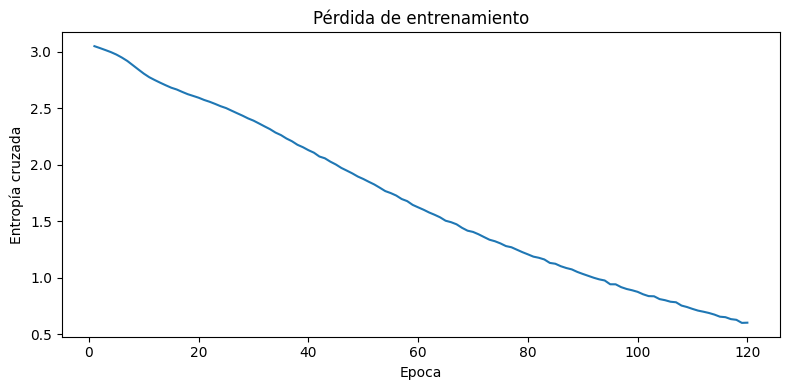

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epocas + 1), historial)
plt.xlabel("Epoca")
plt.ylabel("Entropía cruzada")
plt.title("Pérdida de entrenamiento")
plt.tight_layout()
plt.show()


In [12]:
model.eval()
with torch.no_grad():
    logits_test = model(X_test_t.to(device))
    y_pred = torch.argmax(logits_test, dim=1).cpu().numpy()

k = len(categorias)
matriz = np.zeros((k, k), dtype=int)
for real, pred in zip(y_test, y_pred):
    matriz[int(real), int(pred)] += 1

exactitud = np.trace(matriz) / matriz.sum()
precisiones = []
sensibilidades = []
f1s = []

for i in range(k):
    tp = matriz[i, i]
    fp = matriz[:, i].sum() - tp
    fn = matriz[i, :].sum() - tp
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    sensibilidad = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    if precision + sensibilidad == 0:
        f1 = 0.0
    else:
        f1 = 2 * precision * sensibilidad / (precision + sensibilidad)
    precisiones.append(precision)
    sensibilidades.append(sensibilidad)
    f1s.append(f1)

print("Exactitud:", round(float(exactitud), 4))
print("Precision macro:", round(float(np.mean(precisiones)), 4))
print("Sensibilidad macro:", round(float(np.mean(sensibilidades)), 4))
print("F1 macro:", round(float(np.mean(f1s)), 4))
print()
for i, nombre in enumerate(categorias):
    print(
        nombre,
        "precision", round(precisiones[i], 4),
        "sensibilidad", round(sensibilidades[i], 4),
        "f1", round(f1s[i], 4),
    )


Exactitud: 0.3654
Precision macro: 0.358
Sensibilidad macro: 0.3643
F1 macro: 0.3501

gcrfin precision 0.3333 sensibilidad 0.25 f1 0.2857
whcspa precision 0.1667 sensibilidad 0.2 f1 0.1818
amepip precision 0.4 sensibilidad 0.4 f1 0.4
sposan precision 0.6667 sensibilidad 0.8 f1 0.7273
rocwre precision 0.0 sensibilidad 0.0 f1 0.0
brebla precision 0.4 sensibilidad 0.8 f1 0.5333
daejun precision 0.0 sensibilidad 0.0 f1 0.0
foxspa precision 0.3333 sensibilidad 0.2 f1 0.25
clanut precision 1.0 sensibilidad 0.8 f1 0.8889
moublu precision 0.5 sensibilidad 0.8 f1 0.6154
casfin precision 0.6 sensibilidad 0.6 f1 0.6
mallar3 precision 0.6667 sensibilidad 0.8 f1 0.7273
herthr precision 0.0 sensibilidad 0.0 f1 0.0
amerob precision 0.3333 sensibilidad 0.2 f1 0.25
yerwar precision 0.2857 sensibilidad 0.4 f1 0.3333
yelwar precision 0.0 sensibilidad 0.0 f1 0.0
dusfly precision 0.3333 sensibilidad 0.4 f1 0.3636
mouchi precision 0.5 sensibilidad 0.4 f1 0.4444
orcwar precision 0.3333 sensibilidad 0.2 f1 0.

## 13. Matriz de confusión

Cada fila es la especie real y cada columna es la especie predicha. La diagonal son los aciertos.


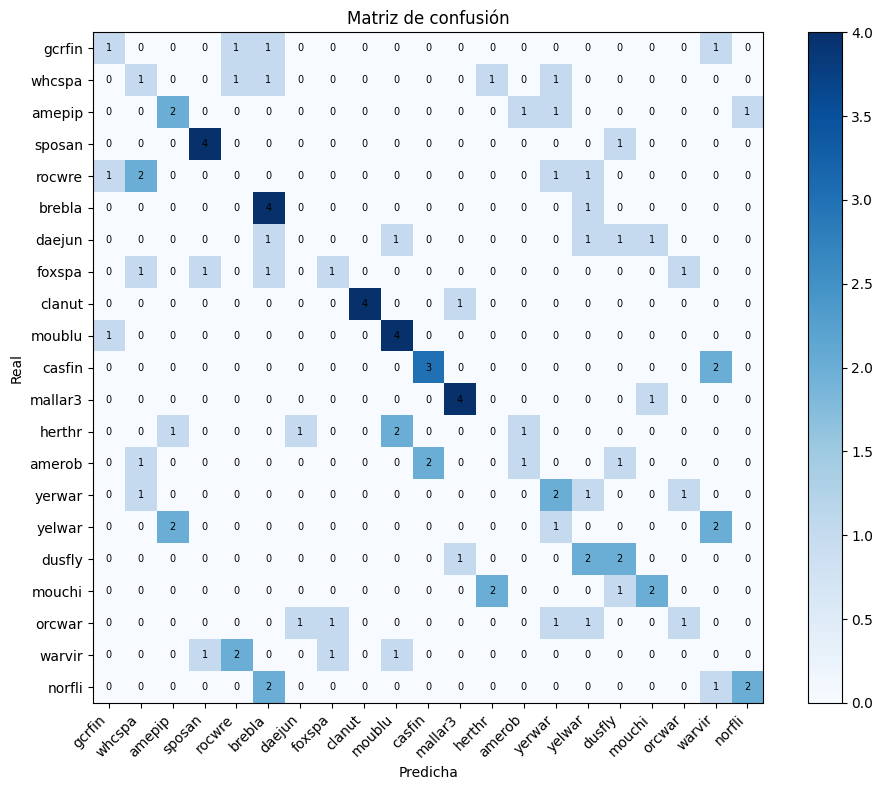

In [13]:
plt.figure(figsize=(10, 8))
plt.imshow(matriz, cmap="Blues")
plt.xticks(range(k), categorias, rotation=45, ha="right")
plt.yticks(range(k), categorias)
plt.xlabel("Predicha")
plt.ylabel("Real")
plt.title("Matriz de confusión")
for fila in range(k):
    for columna in range(k):
        plt.text(columna, fila, str(matriz[fila, columna]), ha="center", va="center", fontsize=7)
plt.colorbar()
plt.tight_layout()
plt.show()


In [14]:
indice_nuevo = int(elegidos[idx_test[0]])
muestra_nueva = train[indice_nuevo]
senal_nueva = np.asarray(muestra_nueva["audio"]["array"], dtype=np.float32)
vector_nuevo = vector_mfcc(senal_nueva)
vector_nuevo = (vector_nuevo - media) / desviacion
tensor_nuevo = torch.tensor(vector_nuevo, dtype=torch.float32).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits_nuevo = model(tensor_nuevo)
    desplazado = logits_nuevo - logits_nuevo.max()
    probabilidad = torch.exp(desplazado)
    probabilidad = (probabilidad / probabilidad.sum()).cpu().numpy()[0]

clase_predicha = categorias[int(np.argmax(probabilidad))]
print("Indice en el dataset:", indice_nuevo)
print("Clase real:", categorias[muestra_nueva["ebird_code"]])
print("Clase predicha:", clase_predicha)
for nombre, valor in zip(categorias, probabilidad):
    print(nombre, round(float(valor), 4))


Indice en el dataset: 5259
Clase real: yelwar
Clase predicha: warvir
gcrfin 0.001
whcspa 0.0017
amepip 0.0168
sposan 0.2883
rocwre 0.0012
brebla 0.0002
daejun 0.0
foxspa 0.001
clanut 0.0009
moublu 0.0001
casfin 0.0002
mallar3 0.0001
herthr 0.0062
amerob 0.0002
yerwar 0.007
yelwar 0.0007
dusfly 0.1974
mouchi 0.0031
orcwar 0.0001
warvir 0.4457
norfli 0.0283


In [15]:
torch.save(model.state_dict(), "pesos_red_audio.pt")
print("Pesos guardados en pesos_red_audio.pt")


Pesos guardados en pesos_red_audio.pt


## 16. Conclusión

El modelo clasifica 21 especies de BirdSet HSN. Cada canto entra desde el dataset de Hugging Face, se recorta a 5 segundos y se convierte en un vector de medias y desviaciones MFCC, normalizado con los datos de entrenamiento.

La red usa la hipótesis lineal $z = Wx + b$ en cada capa, ReLU en las capas ocultas y softmax junto con la entropía cruzada para elegir una especie. Los pesos se ajustan con descenso por el gradiente y una penalización L2 pequeña.

La exactitud, la precisión, la sensibilidad y el F1 se leen de la matriz de confusión. Esas métricas corresponden a una salida discreta. El error cuadrático y el $R^2$ quedan para los laboratorios de regresión, donde la salida era un número.
